# Captum tour: expressivity bottleneck

The two models are described in `01_data_and_models`. This file uses no Captum: the measure is in
`expressivity.py` (plain PyTorch), so it works on any model. `08_digits_bottleneck` runs it on another dataset.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

## 24. Expressivity bottleneck: would more units help?

Captum explains what the model already does; it can't say what a layer is **missing**. This section asks that
directly, following TINY (Verbockhaven et al., *Growing Tiny Networks*, TMLR 2024). It needs one pass over 2048
training examples (16 minibatches): no checkpoints, no retraining.

The question for a layer, e.g. `fc2`: the loss wants `fc3`'s pre-activation to move by `v`. How much of that move
can **no** weight change reach, because `fc2` doesn't give `fc3` enough directions? And how much would new `fc2`
units recover?

```python
for layer in [fc1, fc2, fc3]:            # e.g. fc2:
    a = input of layer                   # h1          (n, 64)
    h = output of layer                  # h2          (n, 3) or (n, 64)
    v = -grad(loss, next pre-activation) # fc3_pre     (n, 64): where the loss wants it to move, per example

    # 1. retune the next layer's weights as well as possible
    dW   = pinv(h) @ v                   # (width, 64): the best change to fc3's weights
    rest = v - h @ dW                    # the part no change to fc3's weights can produce
    unreachable = sum(rest**2) / sum(v**2)

    # 2. what one new unit in this layer could do (it reads a, writes into fc3_pre)
    S, N = a.T @ a / n,  a.T @ rest / n
    lam, U, V = svd(S^-1/2 @ N)
    headroom = lam[0]**2                 # how fast the loss starts falling if the best new unit is added
    alpha, omega = S^-1/2 @ U[:, 0] * sqrt(lam[0]),  V[0] * sqrt(lam[0])     # its in- and out-weights

    # 3. check: really add it, as 2 ReLU units  relu(a@alpha)*omega + relu(-a@alpha)*(-omega),
    #    pick its size on these 2048 examples, then measure the loss on 2048 other training examples
```

In `expressivity.py` the same thing is three calls; every sum above is accumulated batch by batch:

```python
res = measure(model, sites, batches)                 # sites: [Site("fc2", "fc3"), ...]
res["fc2"].headroom, res["fc2"].unreachable
check(model, Site("fc2", "fc3"), res["fc2"], fit_batches, check_batches)   # step 3
bigger = grow(model, Site("fc2", "fc3"), res["fc2"], scale=...)            # the grown model itself
```

* plot 1: per layer, both models: unreachable share, headroom, and the measured loss drop from adding the unit
* plot 2: headroom at every epoch: how early the flag appears

bottleneck + check in 0.1s


unreachable   headroom  before       drop    scale  drop_%
model  layer                                                            
narrow fc1          0.957  1.920e-03   0.468 -1.500e-04    0.300  -0.032
       fc2          0.994  3.288e-02   0.468  4.887e-02    3.000  10.436
       fc3          0.963  0.000e+00   0.468  0.000e+00    0.003   0.000
wide   fc1          0.960  1.400e-04   0.055 -2.070e-03   10.000  -3.750
       fc2          0.961  1.300e-04   0.055 -3.900e-04   30.000  -0.707
       fc3          0.961  1.000e-04   0.055 -8.030e-03  100.000 -14.548

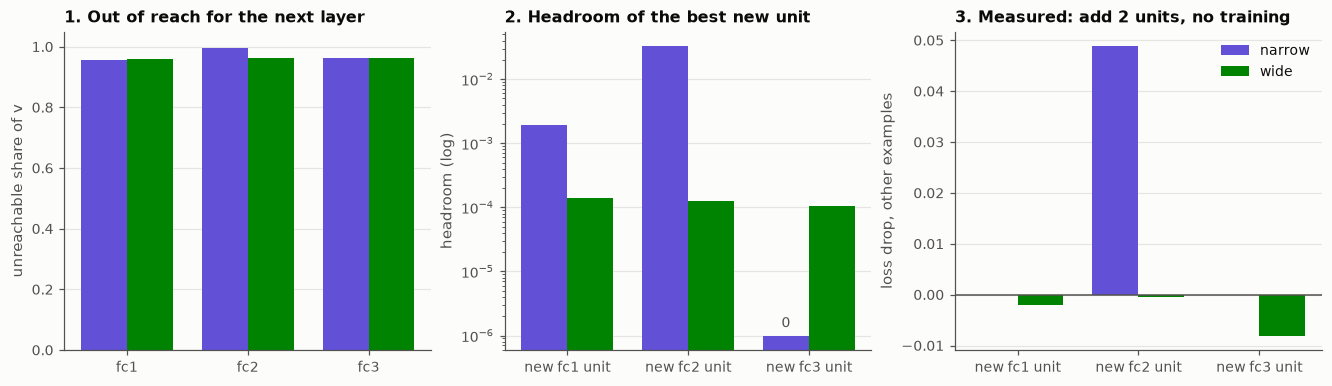

In [2]:
t0 = time.time()
BN = {name: measure(m, SITES, FIT) for name, m in MODELS.items()}
bn_table = pd.DataFrame([dict(model=name, layer=s.layer, unreachable=BN[name][s.layer].unreachable,
                              headroom=BN[name][s.layer].headroom,
                              **check(MODELS[name], s, BN[name][s.layer], FIT, CHECK))
                         for name in WIDTH for s in SITES]).set_index(["model", "layer"])
bn_table["drop_%"] = 100 * bn_table["drop"] / bn_table["before"]
print(f"bottleneck + check in {time.time() - t0:.1f}s")
display(bn_table.drop(columns=["after"]).round(5))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
xs = np.arange(len(LAYERS))
for ax, col, label in [(axes[0], "unreachable", "unreachable share of v"),
                       (axes[1], "headroom", "headroom (log)"),
                       (axes[2], "drop", "loss drop, other examples")]:
    for k, name in enumerate(["narrow", "wide"]):
        vals = np.array([bn_table.loc[(name, layer), col] for layer in LAYERS])
        if col == "headroom":
            vals = np.maximum(vals, 1e-6)
            for j in np.flatnonzero(vals <= 1e-6):  # mark the layers where the headroom is exactly 0
                ax.text(j + (k - 0.5) * 0.38, 1.2e-6, "0", ha="center", va="bottom", fontsize=9, color=INK2)
        ax.bar(xs + (k - 0.5) * 0.38, vals, width=0.38, color=MODEL_COLOR[name], label=name)
    ax.set_xticks(xs, [f"new {layer} unit" if col != "unreachable" else layer for layer in LAYERS])
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(label)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("1. Out of reach for the next layer", loc="left")
axes[1].set_yscale("log")
axes[1].set_title("2. Headroom of the best new unit", loc="left")
axes[2].axhline(0, color=INK2, lw=1)
axes[2].set_title("3. Measured: add 2 units, no training", loc="left")
axes[2].legend(loc="upper right")
plt.show()

**How early does it show?** The same computation on the checkpoint of every epoch (one pass over the same 2048
examples each time).

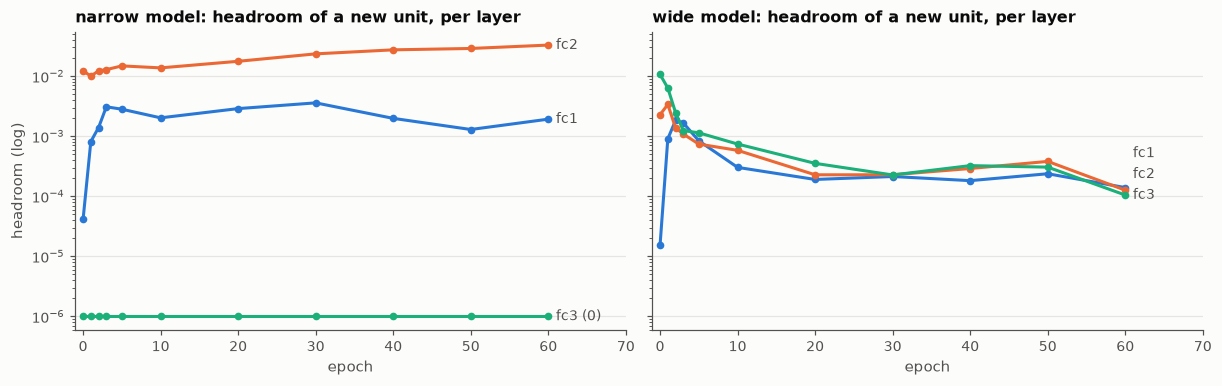

In [3]:
BN_EPOCHS = [0, 1, 2, 3, 5, 10, 20, 30, 40, 50, 60]
bn_hist = {(name, e): measure(load(WIDTH[name], CKPTS[name][e]), SITES, FIT) for name in WIDTH for e in BN_EPOCHS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    items = []
    for layer in LAYERS:
        ys = [max(bn_hist[(name, e)][layer].headroom, 1e-6) for e in BN_EPOCHS]
        ax.plot(BN_EPOCHS, ys, marker="o", ms=4, color=LAYER_COLOR[layer])
        items.append((BN_EPOCHS[-1], ys[-1], layer if ys[-1] > 1e-6 else f"{layer} (0)"))
    ax.set_yscale("log")
    ax.set_xlim(-1, 70)
    ax.set_xlabel("epoch")
    ax.set_title(f"{name} model: headroom of a new unit, per layer", loc="left")
    end_labels(ax, items)
axes[0].set_ylabel("headroom (log)")
plt.show()

* **Plot 1, left: `rest` alone says nothing.** 96–99% of `v` is out of reach in every layer of both models.
  That is expected: once a layer's weights have converged, their gradient `h.T @ v` is about zero, so `v` has
  almost nothing in the directions `h` offers. What matters is whether new units can reach the rest.
* **Plot 1, middle: headroom flags only narrow `fc2`.** It is 16× above narrow `fc1` and over 200× above every
  layer of the wide model. Narrow `fc3` has none: a new `fc3` unit could only read `fc2`'s 3 numbers, which is
  where the information was already lost.
* **Plot 1, right: the prediction holds.** Adding the suggested 2 units to narrow `fc2`, with no training, lowers the
  loss on other training examples by 10%. Anywhere else the change is zero or negative: there the new unit only
  fits noise in the 2048 examples it was sized on.
* **Plot 2: it shows within a few epochs.** An untrained model has headroom everywhere (wide `fc3` starts as high as
  narrow `fc2`). In the wide model it then falls in every layer. In the narrow model `fc2` leads from epoch 0 and
  keeps rising while the loss falls; by epoch 3 it is 10× above every layer of the wide model.
* Use at least ~1000 examples (8 or more minibatches). With 512, the estimate of the new unit's 65 × 64 weights
  picks up noise, and the check fails.
* It is a first-order, one-unit test: it finds the layer where *one more direction* pays off now. It doesn't say
  how wide the layer should end up (§26).